# Clase 5 — Explorar a ciegas

**Mini curso "RL a ciegas" · vía profunda (notebooks)**

En la clase 4 el agente aprendía con Q-learning *porque alguna vez llegaba a la salida por casualidad*.
¿Qué pasa si la cueva es más grande y la casualidad no alcanza? Ese es el **problema de exploración difícil**
(*hard-exploration problem*) con **recompensa escasa** (*sparse reward*): la única señal está en la salida, y
para verla hay que llegar al menos una vez.

Es el mismo problema que hizo famoso al juego de Atari *Montezuma's Revenge*: durante años, los mejores agentes
de Deep RL sacaban **0 puntos**, porque nunca encontraban la primera llave.

Hoy vamos a comparar cuatro formas de explorar, todas con **el mismo presupuesto** de pasos:

| Paso | Método | Idea en una línea |
|---|---|---|
| 2 | ε-greedy | a veces, una acción al azar |
| 3 | Curiosidad por conteo | premio extra por ir adonde casi no fui |
| 4 | Optimismo inicial | suponer que lo desconocido es bueno |
| 5 | Go-Explore | recordar lugares, **volver** a uno prometedor y explorar desde ahí |

## Preparación

La primera celda escribe el entorno `cave_env.py` (el mismo de todas las clases), así el notebook funciona solo en Colab.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Imports y semillas fijas, para que todos veamos los mismos resultados.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

np.random.seed(0)
plt.rcParams["figure.dpi"] = 90

### Herramientas

Esta celda define las funciones largas (Q-learning, Go-Explore, dibujos). **No hace falta leerla**: en la clase
solo las vamos a *usar* y mirar los resultados. En Colab aparece plegada.

In [3]:
#@title Herramientas (plegable)
# Herramientas: no hace falta leer esto
from collections import deque

COLORES = {"ε-greedy": "#2a78d6", "Conteo (curiosidad)": "#eb6834",
           "Optimismo inicial": "#1baf7a", "Go-Explore": "#eda100"}

# Una cueva más grande: un laberinto con muchos callejones sin salida.
CUEVA_GRANDE = [
    "#########################",
    "#S..#.........#.........#",
    "#.#.#####.###.###.#####.#",
    "#...#.....#.........#...#",
    "#.###.#####.###.#.#.#.###",
    "#.#...#.........#...#...#",
    "#.#.#.#.#.###.#.#.#.#.#.#",
    "#.....#...#...#.#...#.#.#",
    "#######.###.###.###.#.#.#",
    "#...#.........#.....#.#.#",
    "#.###.#####.#.#####.#.#.#",
    "#...........#..........G#",
    "#########################",
]

def distancias(env):
    """BFS desde la entrada: cantidad mínima de pasos hasta cada casilla."""
    d = {env.start: 0}; q = deque([env.start])
    while q:
        s = q.popleft()
        for a in range(4):
            s2, _ = env._move(s, a)
            if s2 not in d:
                d[s2] = d[s] + 1; q.append(s2)
    return d

def caminar_al_azar(env, episodios=300, seed=0):
    """Fracción de episodios en que un agente al azar llega a la salida, y visitas por casilla."""
    rng = np.random.default_rng(seed); N = np.zeros(env.nS); exitos = 0
    for _ in range(episodios):
        s = env.reset(); N[s] += 1
        while True:
            s, r, done, info = env.step(rng.integers(4)); N[s] += 1
            if done:
                exitos += info["reached_goal"]; break
    return exitos / episodios, N

def q_learning(env, episodios=200, alpha=0.5, gamma=0.9, eps=0.1, beta=0.0, q0=0.0, seed=0):
    """Q-learning tabular con ε-greedy.
    beta > 0  -> suma recompensa intrínseca beta/sqrt(N(s')) (curiosidad por conteo).
    q0  > 0   -> inicialización optimista de la tabla Q.
    Devuelve dict con Q, N (visitas), exito (por episodio), pasos (por episodio)."""
    rng = np.random.default_rng(seed)
    Q = np.full((env.nS, env.nA), float(q0)); Q[env.goal] = 0.0
    N = np.zeros(env.nS); exito, pasos = [], []
    for ep in range(episodios):
        s = env.reset(); N[s] += 1
        while True:
            if rng.random() < eps:
                a = rng.integers(env.nA)
            else:   # desempate al azar entre las mejores acciones
                a = rng.choice(np.flatnonzero(Q[s] == Q[s].max()))
            s2, r, done, info = env.step(a); N[s2] += 1
            r_total = r + (beta / np.sqrt(N[s2]) if beta > 0 else 0.0)
            fin = info["reached_goal"]
            objetivo = r_total + (0.0 if fin else gamma * Q[s2].max())
            Q[s, a] += alpha * (objetivo - Q[s, a])
            s = s2
            if done:
                exito.append(fin); pasos.append(env.t); break
    return dict(Q=Q, N=N, exito=np.array(exito), pasos=np.array(pasos))

def pasos_hasta_salida(res):
    """Pasos de entorno gastados hasta la primera vez que se llega a la salida (None si nunca)."""
    if not res["exito"].any():
        return None
    k = int(np.argmax(res["exito"]))
    return int(res["pasos"][:k + 1].sum())

def varias_semillas(env, semillas=range(8), **kw):
    return [q_learning(env, seed=s, **kw) for s in semillas]

def resumen(nombre, resultados):
    encontraron = [pasos_hasta_salida(r) for r in resultados]
    ok = [p for p in encontraron if p is not None]
    ultimos = np.mean([r["exito"][-50:].mean() for r in resultados])
    txt = f"{nombre:22s} encontró la salida en {len(ok)}/{len(resultados)} semillas"
    if ok:
        txt += f" | pasos hasta la 1ª salida (mediana): {int(np.median(ok)):,}"
    txt += f" | éxito en los últimos 50 episodios: {ultimos:.0%}"
    print(txt)

def mapa_visitas(env, N, ax, titulo):
    """Mapa de calor de log10(visitas). Las casillas nunca visitadas quedan negras (a oscuras)."""
    v = np.where(N > 0, np.log10(1 + N), np.nan)
    env.plot(values=v, ax=ax, title=titulo, cmap="viridis")

def curva_exito(resultados, ax, nombre, ventana=10):
    e = np.mean([r["exito"] for r in resultados], axis=0)
    suav = np.convolve(e, np.ones(ventana) / ventana, mode="valid")
    ax.plot(np.arange(len(suav)) + ventana, suav, lw=2, color=COLORES[nombre], label=nombre)

# ---------- Go-Explore ----------
def go_explore(env, iteraciones=250, k=30, seed=0, fotos=()):
    """Mini Go-Explore (fase 1) para un entorno determinista.
    Archivo: celda -> {trayectoria para llegar, veces vista, iteración en que se agregó}.
    Cada iteración: elegir celda (peso ~ 1/sqrt(vistas+1)), VOLVER restaurando el estado,
    explorar k pasos al azar, actualizar el archivo."""
    rng = np.random.default_rng(seed)
    archivo = {env.start: dict(tray=[env.start], vistas=1, nacio=0)}
    pasos, hallazgo, instantaneas, ejemplo = 0, None, {}, None
    for it in range(1, iteraciones + 1):
        celdas = list(archivo)
        w = np.array([1 / np.sqrt(archivo[c]["vistas"] + 1) for c in celdas]); w /= w.sum()
        c = celdas[rng.choice(len(celdas), p=w)]
        # 1) VOLVER: el entorno es determinista, restauramos el estado directamente
        env.reset(); env.s = c
        tray = list(archivo[c]["tray"]); explorado = [c]
        # 2) EXPLORAR: k pasos al azar desde ahí
        for _ in range(k):
            s2, r, done, info = env.step(rng.integers(4)); pasos += 1
            tray.append(s2); explorado.append(s2)
            if s2 in archivo:     # 3) ACTUALIZAR: contar visita, quedarse con el camino más corto
                archivo[s2]["vistas"] += 1
                if len(tray) < len(archivo[s2]["tray"]):
                    archivo[s2]["tray"] = list(tray)
            else:
                archivo[s2] = dict(tray=list(tray), vistas=1, nacio=it)
            if info["reached_goal"]:
                if hallazgo is None:
                    hallazgo = dict(iteracion=it, pasos=pasos)
                break
        if 20 <= it <= 60 and (ejemplo is None or len(set(explorado)) > len(set(ejemplo["explorar"]))):
            ejemplo = dict(volver=list(archivo[c]["tray"]), explorar=explorado, celda=c, iteracion=it)
        if it in fotos or (hallazgo is not None and hallazgo["iteracion"] == it):
            instantaneas[it] = {s: d["nacio"] for s, d in archivo.items()}
    return dict(archivo=archivo, hallazgo=hallazgo, fotos=instantaneas, ejemplo=ejemplo)

def mapa_archivo(env, nacio, ax, titulo):
    v = np.full(env.nS, np.nan)
    for s, it in nacio.items():
        v[s] = it
    env.plot(values=v, ax=ax, title=titulo, cmap="plasma")

def marcar(env, ax, s, texto="★"):
    r, c = env.free[s]
    ax.text(c, r, texto, ha="center", va="center", color="#eda100", fontsize=16, weight="bold")

def podar_bucles(tray):
    """Quita los bucles de una trayectoria (válido porque la cueva es determinista)."""
    out = []
    for s in tray:
        if s in out:
            out = out[:out.index(s) + 1]
        else:
            out.append(s)
    return out

## Paso 1 — Una cueva más grande

La cueva de las clases anteriores es chica: un agente al azar llega a la salida en ~5% de los intentos, y con eso
Q-learning ya tiene de dónde aprender. Para ver el problema de exploración necesitamos una cueva donde **el azar no alcance**.

Armamos un laberinto más grande y lo dibujamos con la misma `env.plot` de siempre. Recompensa **solo en la salida**
(`step_reward=0`) y un máximo de 300 pasos por episodio.

Casillas libres: 155  |  alcanzables desde la entrada: 155  (conectada: True)
Camino más corto a la salida: 44 pasos (y tenemos 300 por episodio)


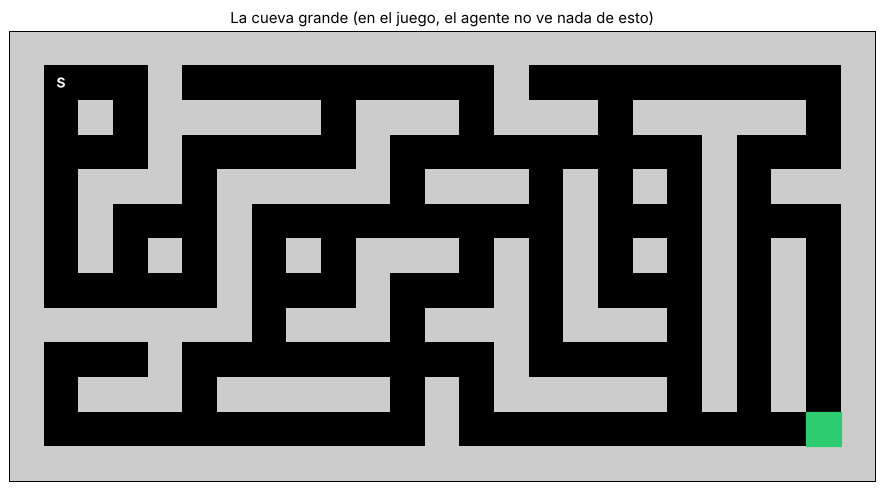

In [4]:
env = CaveEnv(cave_map=CUEVA_GRANDE, step_reward=0.0, max_steps=300)
d = distancias(env)
print(f"Casillas libres: {env.nS}  |  alcanzables desde la entrada: {len(d)}  (conectada: {len(d) == env.nS})")
print(f"Camino más corto a la salida: {d[env.goal]} pasos (y tenemos 300 por episodio)")

env.plot(title="La cueva grande (en el juego, el agente no ve nada de esto)");

Ahora, 300 episodios con un agente que se mueve **al azar**. Pintamos cuántas veces pisó cada casilla
(escala logarítmica; **negro = nunca la pisó**).

Agente al azar: llegó a la salida en 0% de 300 episodios


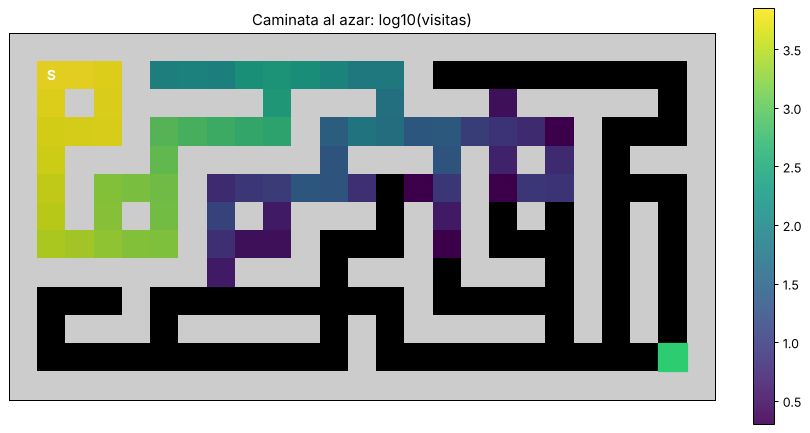

In [5]:
tasa, N_azar = caminar_al_azar(env, episodios=300)
print(f"Agente al azar: llegó a la salida en {tasa:.0%} de 300 episodios")

fig, ax = plt.subplots(figsize=(11, 6))
mapa_visitas(env, N_azar, ax, "Caminata al azar: log10(visitas)");

El azar se queda **pegado a la entrada**: las visitas se concentran cerca de `S` y se apagan con la distancia.
Una caminata al azar se aleja, en promedio, como $\sqrt{t}$ pasos: con 300 pasos, ~17 casillas "en línea recta",
y en un laberinto mucho menos. La salida está a 44.

## Paso 2 — Q-learning con ε-greedy: explorar a ciegas

Usamos el Q-learning de la clase 4 con la regla **ε-greedy** (*epsilon-greedy*): con probabilidad ε una acción al azar,
si no la mejor según la tabla.

Mientras no encuentre la salida, todas las recompensas son 0 → la tabla Q queda en 0 → "la mejor acción" es un empate
y se elige al azar. **Sin recompensa, ε-greedy es una caminata al azar.**

Corremos 8 semillas, 200 episodios cada una (60.000 pasos como máximo) y miramos el mapa de visitas de la primera.

ε-greedy               encontró la salida en 0/8 semillas | éxito en los últimos 50 episodios: 0%


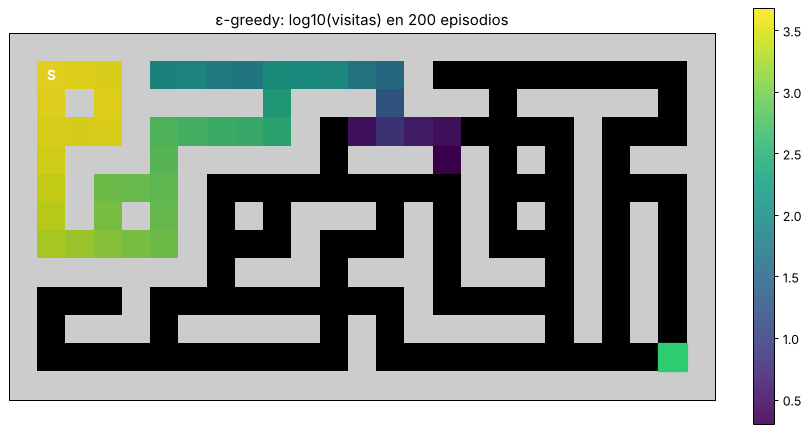

In [6]:
PARAMS = dict(episodios=200, alpha=0.5, gamma=0.9, eps=0.1)

res_eps = varias_semillas(env, **PARAMS)
resumen("ε-greedy", res_eps)

fig, ax = plt.subplots(figsize=(11, 6))
mapa_visitas(env, res_eps[0]["N"], ax, "ε-greedy: log10(visitas) en 200 episodios");

Ninguna semilla encuentra la salida: la mitad derecha de la cueva queda casi a oscuras.

La regla que acabamos de usar:

$$
a_t = \begin{cases} \text{acción al azar} & \text{con prob. } \varepsilon \\ \arg\max_a Q(s_t,a) & \text{con prob. } 1-\varepsilon \end{cases}
$$

El problema no es ε: es que **la exploración no tiene dirección**. El agente no distingue "acá ya estuve mil veces"
de "acá nunca vine".

## Paso 3 — Curiosidad: premiar lo nuevo (recompensa intrínseca por conteo)

Idea: además de la recompensa del entorno, el agente se da a sí mismo un **premio por novedad**. Llevamos la cuenta
$N(s)$ de cuántas veces pisó cada casilla y sumamos una **recompensa intrínseca** (*intrinsic reward*) que se achica
con las visitas. Es lo que en la literatura se llama **curiosidad** (*curiosity*) o bonus de exploración
(*exploration bonus*).

Mismo Q-learning, mismo ε, mismo presupuesto. Solo cambia la recompensa.

Conteo (curiosidad)    encontró la salida en 8/8 semillas | pasos hasta la 1ª salida (mediana): 29,645 | éxito en los últimos 50 episodios: 87%


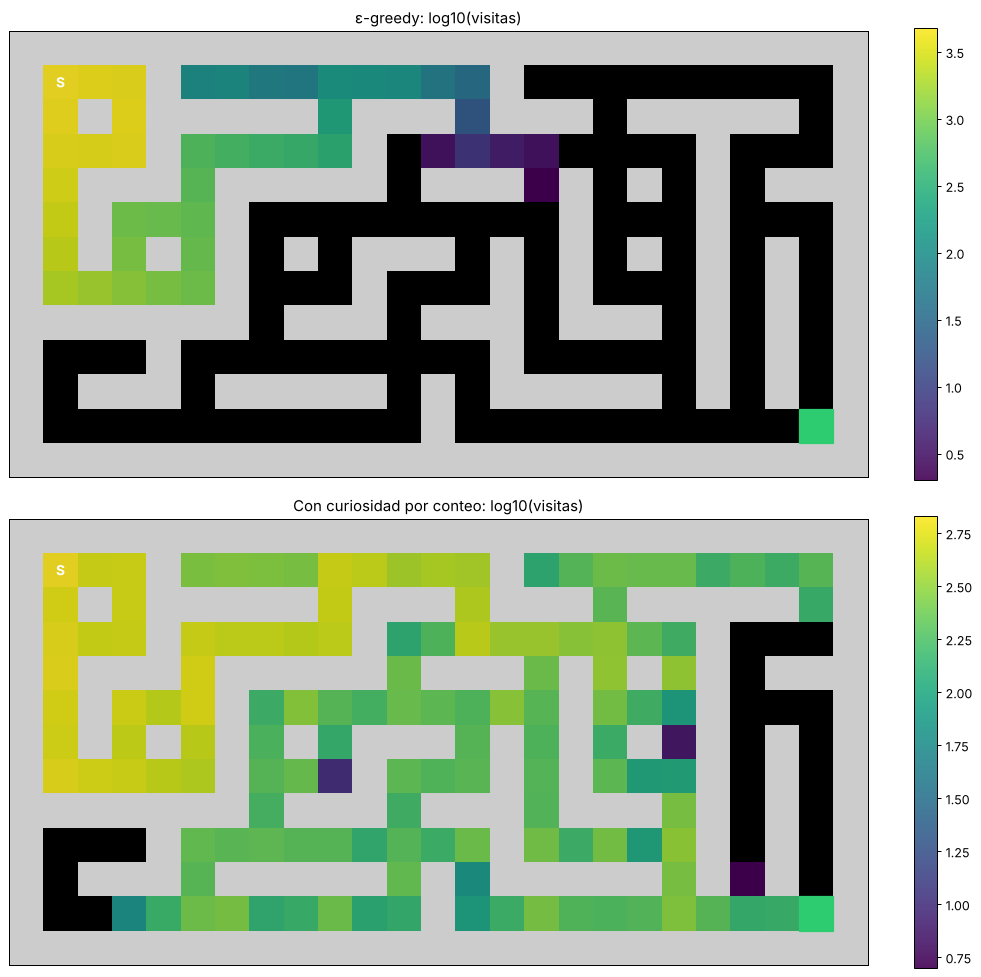

In [7]:
res_cnt = varias_semillas(env, beta=0.1, **PARAMS)
resumen("Conteo (curiosidad)", res_cnt)

fig, axes = plt.subplots(2, 1, figsize=(11, 11))
mapa_visitas(env, res_eps[0]["N"], axes[0], "ε-greedy: log10(visitas)")
mapa_visitas(env, res_cnt[0]["N"], axes[1], "Con curiosidad por conteo: log10(visitas)")
plt.tight_layout();

Con curiosidad el agente **recorre casi toda la cueva** y encuentra la salida en todas las semillas. Lo visitado se vuelve
"aburrido" y el agente es empujado hacia la frontera de lo desconocido. Y como Q-learning *propaga* recompensas hacia atrás,
el premio por novedad de la frontera atrae al agente desde lejos.

La recompensa que aprende el agente:

$$
r_{\text{total}} = \underbrace{r_{\text{entorno}}}_{\text{la salida}} + \underbrace{\frac{\beta}{\sqrt{N(s')}}}_{\text{curiosidad}}
$$

En Atari no se pueden contar pixeles exactos (nunca se repite la misma pantalla), así que se usan *pseudo-conteos* o el
error de predicción de una red (RND, *Random Network Distillation*): **"me sorprende" ≈ "casi no lo vi"**.

### ✍️ Ejercicio

1. Cambiá `beta=0.1` por `beta=1.0`. ¿Cambia cuándo encuentra la salida? (Pista: mientras no hay recompensa externa,
   solo importa el tamaño *relativo* de los premios.)
2. Probá `eps=0.0` (sin acciones al azar). ¿Qué pasa? ¿Por qué un premio *positivo* por lo visitado puede hacer que el
   agente prefiera lo conocido antes que una acción que nunca probó?

In [8]:
# TODO: cambiá beta y/o eps y volvé a correr
prueba = varias_semillas(env, semillas=range(4), episodios=200, alpha=0.5, gamma=0.9, eps=0.1, beta=0.1)
resumen("Conteo (prueba)", prueba)

Conteo (prueba)        encontró la salida en 4/4 semillas | pasos hasta la 1ª salida (mediana): 27,717 | éxito en los últimos 50 episodios: 96%


## Paso 4 — Optimismo inicial: "lo que no conozco es bueno"

Una alternativa más simple: arrancar la tabla con valores **altos** ($Q_0 = 1$, el máximo posible) en vez de 0.
Cada vez que el agente prueba una acción y no pasa nada, ese valor baja. Las acciones nunca probadas siguen
"prometiendo" 1, así que el agente **las va probando todas**. Es el principio de *optimismo ante la incertidumbre*
(*optimism in the face of uncertainty*).

Optimismo inicial      encontró la salida en 8/8 semillas | pasos hasta la 1ª salida (mediana): 5,187 | éxito en los últimos 50 episodios: 100%


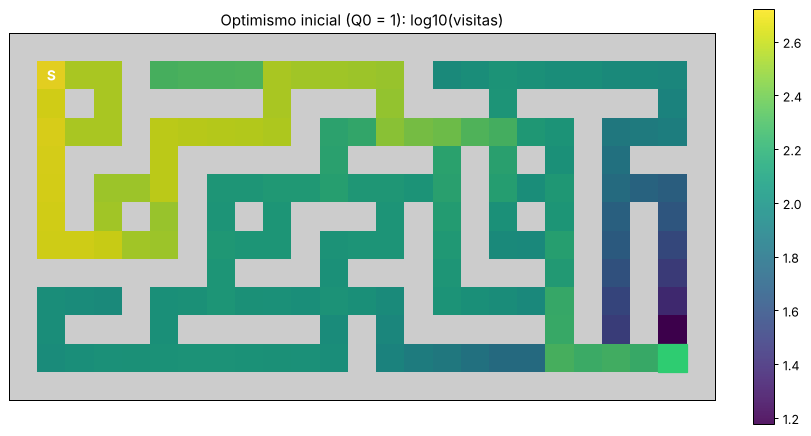

In [9]:
res_opt = varias_semillas(env, q0=1.0, **PARAMS)
resumen("Optimismo inicial", res_opt)

fig, ax = plt.subplots(figsize=(11, 6))
mapa_visitas(env, res_opt[0]["N"], ax, "Optimismo inicial (Q0 = 1): log10(visitas)");

En una tabla chica el optimismo es **excelente**: barre la cueva de forma sistemática y encuentra la salida muy rápido.
¿Por qué no se usa así en Atari? Porque ahí no hay tabla: el valor sale de una red neuronal (clase 6) y no podemos
"poner un 1" en cada pantalla que todavía no vimos. La curiosidad, en cambio, sí se puede aproximar con redes.

## Paso 5 — Go-Explore: primero volver, después explorar

**Go-Explore** (Ecoffet, Huizinga, Lehman, Stanley y Clune, *Nature* 2021) fue el primer método en "resolver"
*Montezuma's Revenge*. Parte de un diagnóstico de por qué fallan los métodos anteriores:

- **Desapego** (*detachment*): la curiosidad "se gasta". Cuando el agente agota la novedad de una zona y se va a otra,
  se *olvida* de que la frontera de la primera zona era prometedora, y ya no tiene incentivo para volver.
- **Descarrilamiento** (*derailment*): aun queriendo volver a un lugar prometedor, el agente lo intenta con su política
  ruidosa (ε-greedy) y se desvía antes de llegar. Explora *desde el lugar equivocado*.

La receta de Go-Explore: **"primero volver, después explorar"** (*first return, then explore*).

1. Guardar un **archivo** (*archive*) de **celdas** visitadas, con la mejor trayectoria para llegar a cada una.
   Acá cada casilla es una celda; en Atari una celda es la pantalla **reducida** (*downsampling*: por ejemplo
   11×8 pixeles con 8 tonos de gris), así pantallas parecidas caen en la misma celda.
2. **Elegir** una celda prometedora: más probabilidad cuanto menos visitada, peso $\propto 1/\sqrt{\text{visitas}+1}$.
3. **Volver** a ella *sin explorar*. Como el entorno es determinista, podemos **restaurar el estado** del simulador
   (en la cueva: `env.s = celda`). Esto elimina el descarrilamiento.
4. **Explorar** desde ahí $k$ pasos al azar.
5. **Actualizar** el archivo: agregar celdas nuevas, quedarse con caminos más cortos. Como nada se olvida, no hay desapego.

Primero miramos **una iteración**: la trayectoria guardada para volver a la celda elegida, y los $k$ pasos de exploración.

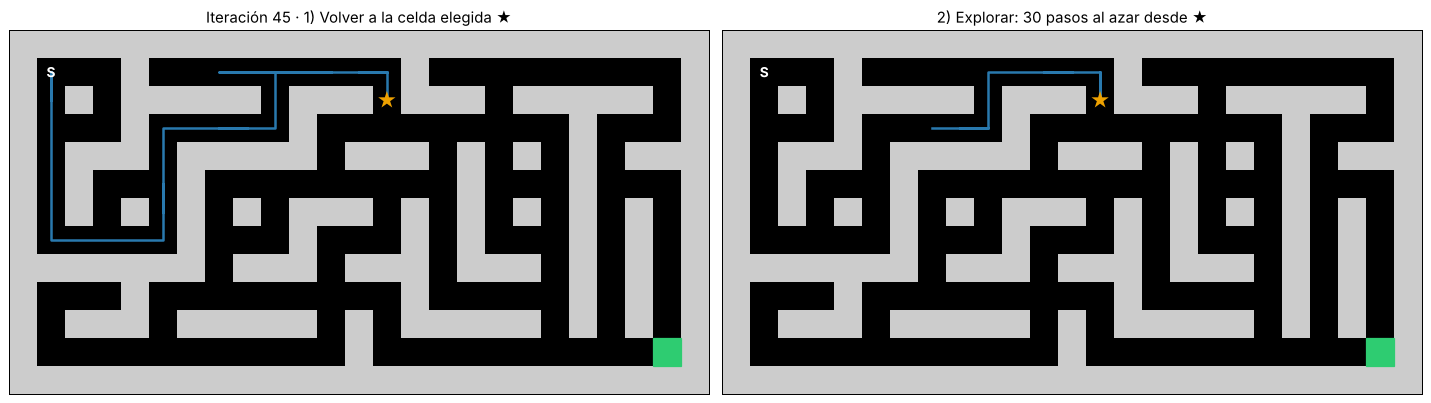

In [10]:
env_ge = CaveEnv(cave_map=CUEVA_GRANDE, step_reward=0.0, max_steps=10**9)  # sin límite: el presupuesto lo fijan las iteraciones
ge = go_explore(env_ge, iteraciones=250, k=30, seed=0, fotos=(10, 40))
ej = ge["ejemplo"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
env_ge.plot(path=ej["volver"], ax=axes[0], title=f"Iteración {ej['iteracion']} · 1) Volver a la celda elegida ★")
env_ge.plot(path=ej["explorar"], ax=axes[1], title="2) Explorar: 30 pasos al azar desde ★")
for ax in axes:
    marcar(env_ge, ax, ej["celda"])
plt.tight_layout();

Ahora la película completa: cómo se **expande el archivo** por la cueva. El color de cada casilla indica
**en qué iteración entró al archivo** (oscuro = temprano, claro = tarde).

Go-Explore encontró la salida en la iteración 118 (3,515 pasos de exploración). Celdas en el archivo al final: 150/155


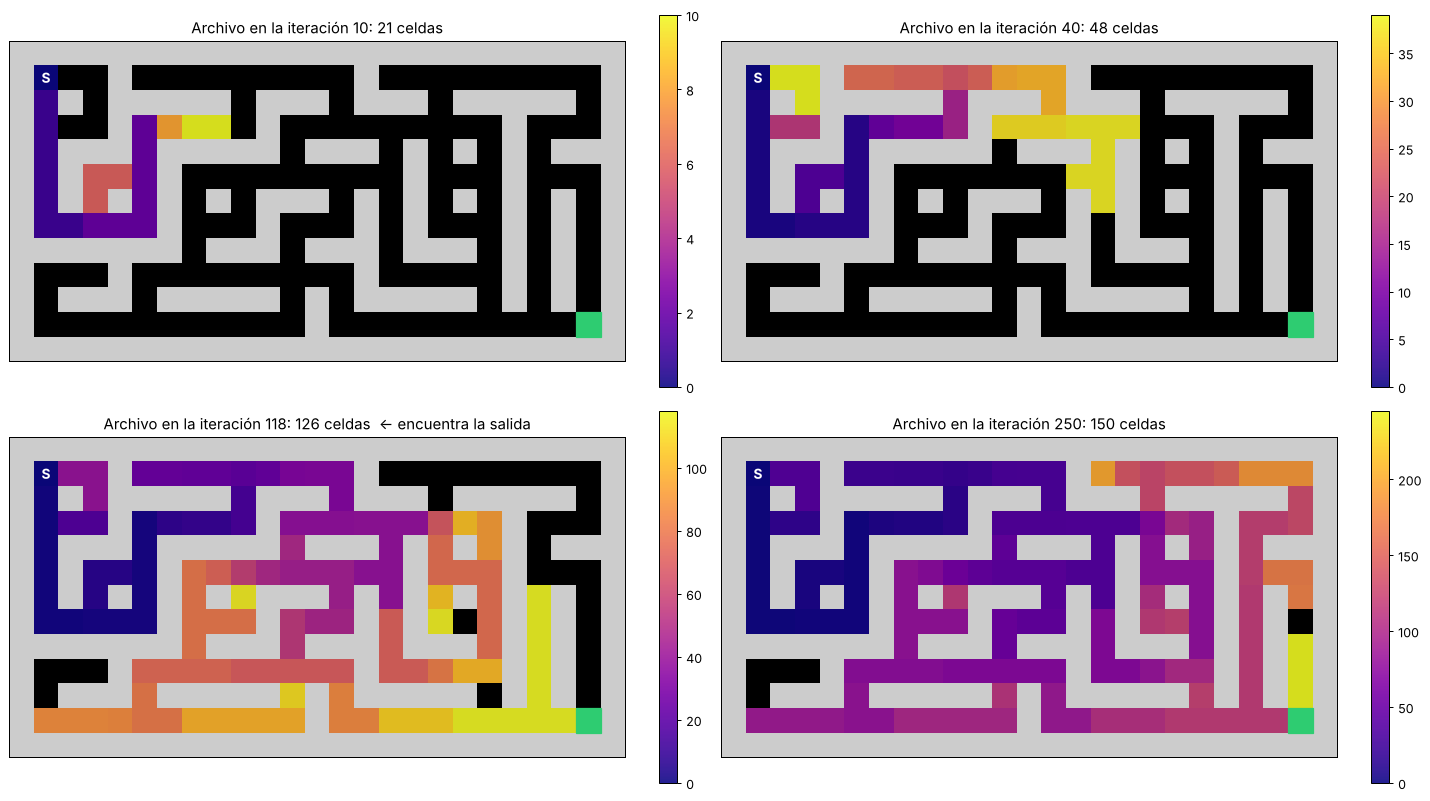

In [11]:
h = ge["hallazgo"]
print(f"Go-Explore encontró la salida en la iteración {h['iteracion']} "
      f"({h['pasos']:,} pasos de exploración). Celdas en el archivo al final: {len(ge['archivo'])}/{env_ge.nS}")

fotos = {**ge["fotos"], 250: {s: d["nacio"] for s, d in ge["archivo"].items()}}

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (it, nacio) in zip(axes.ravel(), sorted(fotos.items())):
    extra = "  ← encuentra la salida" if it == h["iteracion"] else ""
    mapa_archivo(env_ge, nacio, ax, f"Archivo en la iteración {it}: {len(nacio)} celdas{extra}")
plt.tight_layout();

El archivo crece como una mancha que **nunca retrocede**: cada iteración arranca desde el borde de lo conocido,
no desde la entrada. Por eso llega a la salida con pocos miles de pasos, sin ninguna recompensa intrínseca ni tabla Q.

Las semillas cambian el resultado, así que repetimos con 8 semillas, como antes:

In [12]:
ge_semillas = [go_explore(CaveEnv(cave_map=CUEVA_GRANDE, max_steps=10**9), iteraciones=250, k=30, seed=s)
               for s in range(8)]
pasos_ge = [g["hallazgo"]["pasos"] for g in ge_semillas if g["hallazgo"]]
print(f"Go-Explore encontró la salida en {len(pasos_ge)}/8 semillas | "
      f"pasos hasta la 1ª salida (mediana): {int(np.median(pasos_ge)):,}")

Go-Explore encontró la salida en 8/8 semillas | pasos hasta la 1ª salida (mediana): 3,632


### ✍️ Ejercicio

Cambiá `k` (pasos de exploración por iteración) a 5 y a 100. Con `k` chico, ¿hacen falta más iteraciones?
Con `k` grande, ¿se desperdician pasos? (Ojo: lo que comparamos es **pasos**, no iteraciones.)

In [13]:
# TODO: probá k = 5, 30, 100
for k in [30]:
    g = [go_explore(CaveEnv(cave_map=CUEVA_GRANDE, max_steps=10**9), iteraciones=1000, k=k, seed=s) for s in range(4)]
    p = [x["hallazgo"]["pasos"] for x in g if x["hallazgo"]]
    print(f"k = {k:3d}: encontró la salida en {len(p)}/4 semillas, pasos (mediana) = {int(np.median(p)) if p else '-'}")

k =  30: encontró la salida en 4/4 semillas, pasos (mediana) = 3632


## Paso 6 — Fase 2: la trayectoria como demostración

La fase 1 de Go-Explore no produce una *política*: produce un **camino** que funciona en un entorno determinista,
"haciendo trampa" con la restauración de estados. La fase 2 lo convierte en una política de verdad:

- **Robustificación** (*robustification*): entrenar una red con RL usando la trayectoria como **demostración**,
  empezando cerca del final y alejando el punto de partida de a poco (el "algoritmo hacia atrás" de Salimans y Chen, 2018),
  con ruido para que la política sobreviva a un mundo no determinista.
- Más en general, es **aprendizaje por imitación** (*imitation learning*): aprender a partir de ejemplos de alguien
  que ya resolvió la tarea. No lo implementamos acá.

Miramos la demostración que dejó el archivo: tal cual salió, y quitándole los bucles.

Demostración del archivo: 146 pasos | sin bucles: 44 pasos | óptimo: 44 pasos


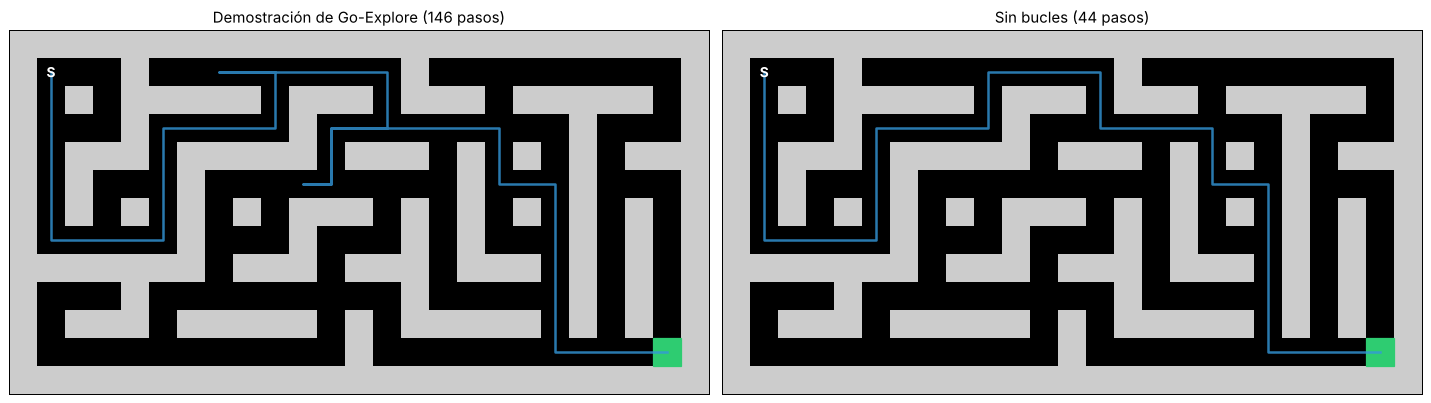

In [14]:
demo = ge["archivo"][env_ge.goal]["tray"]
demo_corta = podar_bucles(demo)
print(f"Demostración del archivo: {len(demo) - 1} pasos | sin bucles: {len(demo_corta) - 1} pasos | "
      f"óptimo: {d[env.goal]} pasos")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
env_ge.plot(path=demo, ax=axes[0], title=f"Demostración de Go-Explore ({len(demo) - 1} pasos)")
env_ge.plot(path=demo_corta, ax=axes[1], title=f"Sin bucles ({len(demo_corta) - 1} pasos)")
plt.tight_layout();

La demostración tiene vueltas (salió de pasos al azar), pero **llega**. Para un agente con recompensa escasa
eso es lo que más cuesta: una vez que existe un camino a la recompensa, aprender a mejorarlo es el problema "fácil"
de las clases 3 y 4.

## Paso 7 — Comparativa final

Mismo presupuesto (hasta 60.000 pasos de entorno), 8 semillas por método.

- **Izquierda**: cuántos pasos hicieron falta para llegar a la salida *por primera vez* (mediana). Menos es mejor.
- **Derecha**: tasa de éxito por episodio para los métodos basados en Q-learning (promedio de 8 semillas,
  media móvil de 10 episodios). Go-Explore no tiene "episodios" en el mismo sentido, así que solo va a la izquierda.

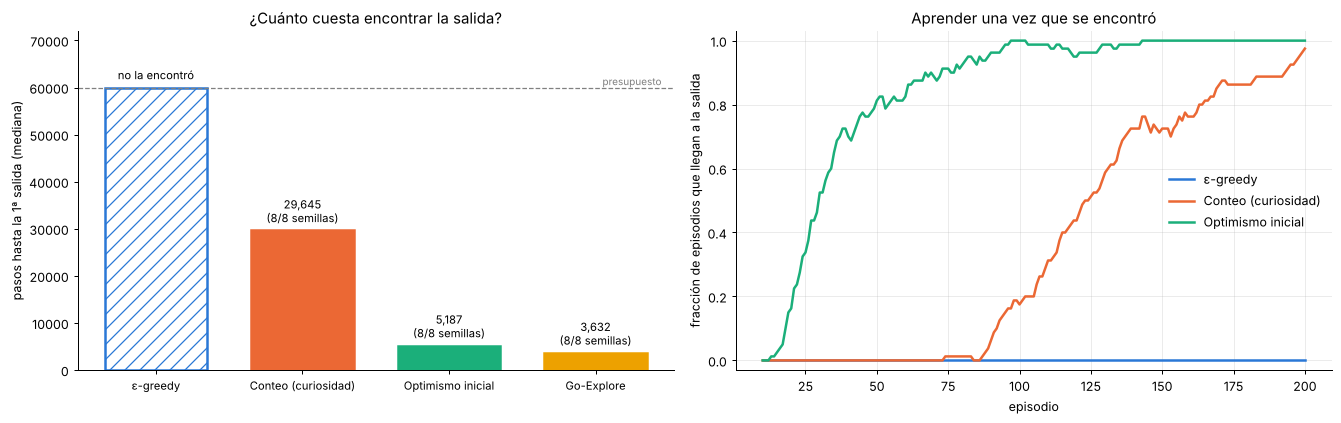

In [15]:
PRESUPUESTO = 200 * 300
metodos = {"ε-greedy": res_eps, "Conteo (curiosidad)": res_cnt, "Optimismo inicial": res_opt}

nombres, medianas, encontro = [], [], []
for nombre, res in metodos.items():
    p = [pasos_hasta_salida(r) for r in res]
    ok = [x for x in p if x is not None]
    nombres.append(nombre); encontro.append(len(ok))
    medianas.append(np.median(ok) if ok else PRESUPUESTO)
nombres.append("Go-Explore"); medianas.append(np.median(pasos_ge)); encontro.append(len(pasos_ge))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for i, (n, m, e) in enumerate(zip(nombres, medianas, encontro)):
    falla = e == 0
    ax.bar(i, m, color="white" if falla else COLORES[n], edgecolor=COLORES[n], hatch="//" if falla else None,
           width=0.7, lw=2)
    ax.text(i, m + PRESUPUESTO * 0.02, "no la encontró" if falla else f"{int(m):,}\n({e}/8 semillas)",
            ha="center", va="bottom", fontsize=9)
ax.axhline(PRESUPUESTO, color="gray", ls="--", lw=1)
ax.text(3.45, PRESUPUESTO, "presupuesto", ha="right", va="bottom", color="gray", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(nombres, fontsize=9)
ax.set_ylabel("pasos hasta la 1ª salida (mediana)"); ax.set_ylim(0, PRESUPUESTO * 1.2)
ax.set_title("¿Cuánto cuesta encontrar la salida?")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
for nombre, res in metodos.items():
    curva_exito(res, ax, nombre)
ax.set_xlabel("episodio"); ax.set_ylabel("fracción de episodios que llegan a la salida")
ax.set_ylim(-0.03, 1.03); ax.set_title("Aprender una vez que se encontró")
ax.legend(frameon=False, loc="center right"); ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout();

**Lectura.** (La curva de ε-greedy queda pegada al 0.)

- **ε-greedy** nunca encuentra la salida: sin recompensa no hay dirección.
- **Curiosidad por conteo** la encuentra siempre, pero tarda: la novedad se propaga despacio y, como vimos, sufre de
  *desapego*.
- **Optimismo inicial** es rapidísimo **en una tabla**; no escala tal cual a pixeles.
- **Go-Explore** la encuentra con pocos miles de pasos, porque **no repite el camino conocido explorando**: vuelve
  directo a la frontera. El precio: necesita poder restaurar estados (un simulador) y una segunda fase para obtener
  una política robusta.

La idea transversal: **explorar bien = saber qué no conozco y tener cómo llegar ahí.**

## Preguntas para pensar

1. Un tutor inteligente (clase 2) quiere saber si un ejercicio nuevo ayuda a los alumnos, pero casi nunca lo propone
   porque "lo conocido funciona". ¿Es un problema de exploración? ¿Qué sería un "bonus por conteo" ahí?
2. Go-Explore restaura el estado del simulador. ¿En qué problemas reales eso es imposible (un robot, una conversación)?
   ¿Qué parte de la idea se puede rescatar igual?
3. En Atari, dos pantallas casi iguales deberían ser la misma celda. ¿Qué pasa si el *downsampling* es demasiado
   grueso? ¿Y demasiado fino?

## Próxima clase

Hasta ahora $Q(s,a)$ fue una **tabla**. Con pixeles hay más estados que átomos en el universo: no entra.
La clase 6 reemplaza la tabla por una **red neuronal** (las mismas que vieron en visión y NLP): eso es **Deep RL** y DQN.